Parameters: 33409

=== STEP 1: Train until L2 ≤ 1e-2 ===


Epoch 500/5000 | Loss 0.000028 | L2 0.005359
✓ Achieved target accuracy!
Step 1 time: 75.80974268913269 seconds

=== STEP 2: Optimized (batched) training ===
Epoch 400/2000 | L2 0.008320
Step 2 time: 247.12239456176758 seconds
Speedup factor: 0.3067700231036093

Final L2: 0.008319777


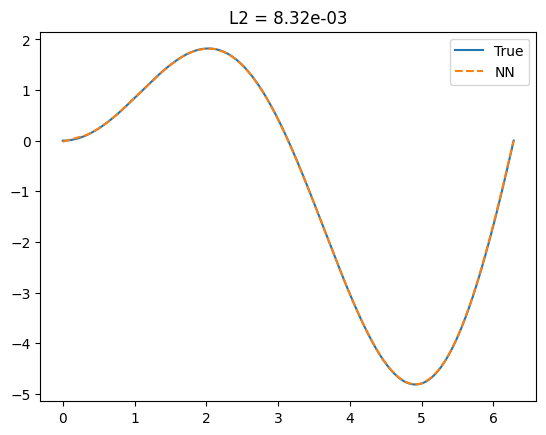

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time
import math

torch.manual_seed(0)
np.random.seed(0)

def f(x):
    return x * np.sin(x)

x_train = np.linspace(0, 2*np.pi, 1024).astype(np.float32)
y_train = f(x_train).astype(np.float32)

def normalize_x(x):
    return 2*(x - 0)/(2*np.pi - 0) - 1

x_train_n = normalize_x(x_train)
x_train_tensor = torch.from_numpy(x_train_n).unsqueeze(1)
y_train_tensor = torch.from_numpy(y_train).unsqueeze(1)

class MLP(nn.Module):
    def __init__(self, in_dim=1, width=128, depth=4, out_dim=1):
        super().__init__()
        
        layers = []
        layers.append(nn.Linear(in_dim, width))
        layers.append(nn.ReLU())  
        
        for _ in range(depth-2):
            layers.append(nn.Linear(width, width))
            layers.append(nn.ReLU())
        
        layers.append(nn.Linear(width, out_dim))
        
        self.net = nn.Sequential(*layers)
        
        for m in self.net.modules():
            if isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, std=0.1)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)

model = MLP(width=128, depth=4)
print("Parameters:", sum(p.numel() for p in model.parameters()))

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

print("\n=== STEP 1: Train until L2 ≤ 1e-2 ===")
start = time.time()

num_epochs = 5000
best_l2 = float('inf')

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()

    pred = model(x_train_tensor)
    loss = criterion(pred, y_train_tensor)

    loss.backward()
    optimizer.step()

    if (epoch+1) % 500 == 0:
        model.eval()
        test_x = np.linspace(0, 2*np.pi, 1000).astype(np.float32)
        test_x_n = normalize_x(test_x).reshape(-1,1)
        test_y = f(test_x).astype(np.float32)

        with torch.no_grad():
            pred_test = model(torch.from_numpy(test_x_n)).squeeze(1).numpy()

        l2_norm = np.linalg.norm(pred_test - test_y) / math.sqrt(len(test_x))

        print(f"Epoch {epoch+1}/{num_epochs} | Loss {loss.item():.6f} | L2 {l2_norm:.6f}")

        if l2_norm < 1e-2:
            print("✓ Achieved target accuracy!")
            break

step1_time = time.time() - start
print("Step 1 time:", step1_time, "seconds")

print("\n=== STEP 2: Optimized (batched) training ===")

from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(x_train_tensor, y_train_tensor)
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

model2 = MLP(width=128, depth=4)
optimizer2 = optim.Adam(model2.parameters(), lr=1e-3)

start = time.time()

for epoch in range(2000):
    for bx, by in dataloader:
        optimizer2.zero_grad()
        pred = model2(bx)
        loss = criterion(pred, by)
        loss.backward()
        optimizer2.step()

    if (epoch+1) % 400 == 0:
        model2.eval()
        with torch.no_grad():
            pred_test = model2(torch.from_numpy(test_x_n)).squeeze(1).numpy()
        l2_norm = np.linalg.norm(pred_test - test_y) / math.sqrt(len(test_x))

        print(f"Epoch {epoch+1}/2000 | L2 {l2_norm:.6f}")

        if l2_norm < 1e-2:
            break

step2_time = time.time() - start
print("Step 2 time:", step2_time, "seconds")
print("Speedup factor:", step1_time/step2_time)

model2.eval()
with torch.no_grad():
    pred = model2(torch.from_numpy(test_x_n)).squeeze(1).numpy()

final_l2 = np.linalg.norm(pred - test_y) / math.sqrt(len(test_x))
print("\nFinal L2:", final_l2)

plt.plot(test_x, test_y, label="True")
plt.plot(test_x, pred, '--', label="NN")
plt.legend()
plt.title(f"L2 = {final_l2:.2e}")
plt.show()
